# 00 — Machine Learning Crash Course (for the practice exam)
Goal: understand **every line** of the exam solution. Work top to bottom (~2–3 h). Run each cell, and
answer each *Check yourself* question **before** opening the answer. Recalling it yourself is what makes it stick.

Map to your slides: W3 Regression · W4 Classification & Metrics · W5 Trees · W6 KNN/SVM · W9 Gradient Descent · W10 Regularisation.

| # | Topic | Exam part |
|---|---|---|
| 1 | What a model is; train/test | all |
| 2 | Linear regression: MSE, normal equation | 1.1 |
| 3 | Gradient descent by hand | 1.1 |
| 4 | R² and RMSE | 1.2 |
| 5 | Multiple, polynomial, overfitting, Ridge | 1.1 |
| 6 | Scaling, one-hot, KNN, ensembles | 1.1 best model |
| 7 | Classification: logistic, confusion matrix, accuracy/precision/recall/F1 | 2.1–2.2 |
| 8 | The sklearn classifiers in one screen | 2.1 |
| 9 | Regression to class (threshold, stacking) | 2.3 |
| 10 | Competition tips | bonus |

In [1]:
import os, warnings; os.environ["LOKY_MAX_CPU_COUNT"] = "4"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(0)

## 1. What a model is
A model is a function `ŷ = f(x; θ)`. **Training** = choosing θ so that ŷ is close to the real y on known data.
* **Regression**: y is a number (price, quality score, kWh).
* **Classification**: y is a category (good/bad, Light/Medium/Maximum).

We hide part of the data (the **test set**) and score the model on it, because a model can memorise training data.
Test score = how it will do on new data.

**Check yourself:** Why not train on 100% of the data and report the training score?

<details><summary>answer</summary>

The model has already seen those rows. A memorising model gets a perfect training score and still fails on new data. The test set shows how it generalises.
</details>

## 2. Linear regression
Model: `ŷ = θ0 + θ1·x`. Loss = **MSE** = mean of (ŷ − y)². The MSE surface is a bowl, so it has exactly one lowest point.

**Normal equation (OLS)** jumps straight to the bottom: add a column of 1s to X (for θ0), then
`θ = (XᵀX)⁻¹ Xᵀ y`.

theta0, theta1 = [3.99278992 2.84636647]  (true: 4, 3)


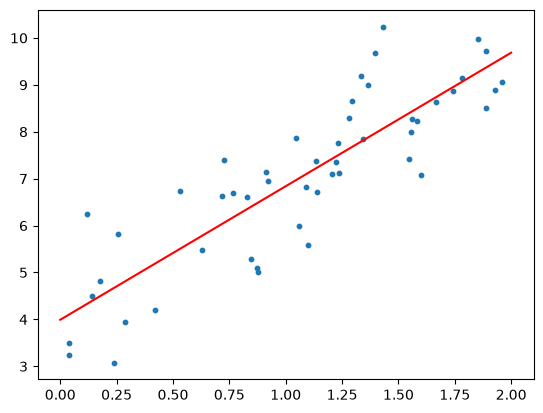

In [2]:
# toy data: y = 4 + 3x + noise
x = 2 * np.random.rand(50)
y = 4 + 3 * x + np.random.randn(50)
Xb = np.c_[np.ones(50), x]                     # [1, x]
theta = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y    # normal equation
print("theta0, theta1 =", theta, " (true: 4, 3)")
plt.scatter(x, y, s=10); xs = np.linspace(0, 2, 10); plt.plot(xs, theta[0] + theta[1] * xs, "r"); plt.show()

**Check yourself:** Why do we add a column of ones to X?

<details><summary>answer</summary>

So the intercept θ0 becomes a normal weight: θ0·1. Then a single matrix product computes θ0 + θ1·x.
</details>

## 3. Gradient descent (W9)
Without the formula, walk downhill instead:
1. Start at θ = 0.
2. Gradient of MSE: `∇ = (2/n) · Xᵀ(Xθ − y)`. It points uphill.
3. Step: `θ ← θ − lr · ∇`. Repeat.

* **lr too small**: very slow. **lr too big**: overshoots and blows up (loss → inf/nan).
* **Batch GD** uses all rows per step. **Stochastic (SGD)** uses 1 random row. **Mini-batch** uses e.g. 32 rows.

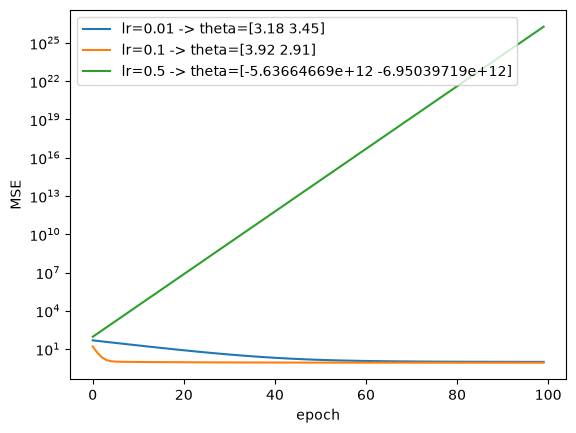

In [3]:
def gd(lr, epochs=100):
    th = np.zeros(2); hist = []
    for _ in range(epochs):
        grad = (2 / len(y)) * Xb.T @ (Xb @ th - y)
        th = th - lr * grad
        hist.append(((Xb @ th - y) ** 2).mean())
    return th, hist

for lr in [0.01, 0.1, 0.5]:
    th, h = gd(lr); plt.plot(h, label=f"lr={lr} -> theta={th.round(2)}")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

**Check yourself:** Your GD loss prints `nan` after a few epochs. What do you change first?

<details><summary>answer</summary>

Lower the learning rate, e.g. ÷10. Also check the features are scaled: unscaled big numbers make the gradients huge.
</details>

## 4. Scoring regression: R² and RMSE
* `RMSE = sqrt(mean((y − ŷ)²))`, in the target's units ("off by 0.6 quality points on average").
* `R² = 1 − SS_res / SS_tot`, where `SS_res = Σ(y − ŷ)²` and `SS_tot = Σ(y − ȳ)²`.
  * 1 = perfect, 0 = no better than always predicting the mean, < 0 = worse than the mean.

In [4]:
def r2(y, p): return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
p = Xb @ theta
from sklearn.metrics import r2_score
print("mine:", r2(y, p), " sklearn:", r2_score(y, p))
print("predict mean ->", r2(y, np.full_like(y, y.mean())))

mine: 0.7373935163162786  sklearn: 0.7373935163162786
predict mean -> 0.0


**Check yourself:** Model A: R² = 0.62. Model B: R² = −0.10. Which is better, and what does B's negative mean?

<details><summary>answer</summary>

A. B's predictions are worse than just guessing the average y for every row.
</details>

## 5. Multiple and polynomial regression, overfitting, Ridge
* **Multiple**: many inputs, `ŷ = θ0 + θ1x1 + … + θnxn`. Same normal equation, X just has more columns.
* **Polynomial**: create new columns x², x³, x1·x2, … and run linear regression on them, so it can bend.
* **Overfitting**: high degree means the curve hits every training point but goes wild between them. Train R² goes up, test R² goes down.
* **Ridge (L2, W10)**: loss + λ·Σθ². Big weights cost extra, so the curve stays smooth. Closed form: `θ = (XᵀX + λI)⁻¹Xᵀy`.

degree  1 lam 0     : train R2 0.542 | test R2 0.490
degree  3 lam 0     : train R2 0.912 | test R2 0.801
degree 15 lam 0     : train R2 0.953 | test R2 -309.196
degree 15 lam 0.001 : train R2 0.939 | test R2 0.810


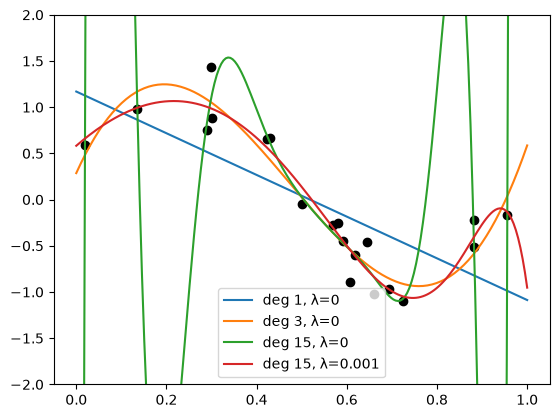

In [5]:
xs_ = np.sort(np.random.rand(20)); ys_ = np.sin(2 * np.pi * xs_) + 0.25 * np.random.randn(20)
xt = np.random.rand(200); yt = np.sin(2 * np.pi * xt) + 0.25 * np.random.randn(200)
def design(x, d): return np.column_stack([x ** k for k in range(d + 1)])
grid = np.linspace(0, 1, 200)
for d, lam in [(1, 0), (3, 0), (15, 0), (15, 1e-3)]:
    A = design(xs_, d); I = np.eye(d + 1); I[0, 0] = 0
    th = np.linalg.solve(A.T @ A + lam * I, A.T @ ys_)
    print(f"degree {d:2d} lam {lam:<6}: train R2 {r2(ys_, A @ th):.3f} | test R2 {r2(yt, design(xt, d) @ th):.3f}")
    plt.plot(grid, design(grid, d) @ th, label=f"deg {d}, λ={lam}")
plt.scatter(xs_, ys_, c="k"); plt.ylim(-2, 2); plt.legend(); plt.show()

**Check yourself:** Degree 15: train R² ≈ 1.0, test R² is bad. Name it and give two fixes.

<details><summary>answer</summary>

Overfitting. Fixes: a lower degree, Ridge (λ > 0), or more data.
</details>

## 6. Data prep, KNN and ensembles (for the "best" model)
* **Standardise**: `z = (x − mean)/std`, with the mean/std from **train only**. Needed for GD, KNN, SVM, Ridge.
* **One-hot**: a text column such as Day = Mon/Tue/… becomes 0/1 columns (`pd.get_dummies`).
* **KNN regression (W6)**: predict = average y of the k nearest training rows. Small k: noisy (overfit). Big k: too smooth.
* **Ensemble**: average two *different* models. Their errors partly cancel, so the score is often higher than either one.
  That's the exam's Model 4.

In [6]:
df = pd.DataFrame({"temp": [30, 25, 35], "day": ["Mon", "Sat", "Mon"]})
print(pd.get_dummies(df, drop_first=True).astype(float))

   temp  day_Sat
0  30.0      0.0
1  25.0      1.0
2  35.0      0.0


**Check yourself:** Why compute mean/std on TRAIN only, and reuse them on TEST?

<details><summary>answer</summary>

Using test statistics leaks test information into training. Every row also has to be transformed the same way, including the teacher's given value.
</details>

## 7. Classification and its metrics (W4)
**Logistic regression**: `p = sigmoid(θᵀx) = 1/(1+e^(−θᵀx))`, a probability. Predict 1 if p ≥ 0.5.

**Confusion matrix** (binary, positive = 1):

| | predicted 0 | predicted 1 |
|---|---|---|
| **actual 0** | TN | FP |
| **actual 1** | FN | TP |

* Accuracy = (TP+TN)/all
* Precision = TP/(TP+FP)
* Recall = TP/(TP+FN)
* F1 = 2PR/(P+R)
* Multi-class **macro F1** = average of each class's F1.

In [7]:
y_true = np.array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0])
y_pred = np.array([1, 1, 0, 0, 0, 0, 0, 0, 0, 1])
TP = ((y_true == 1) & (y_pred == 1)).sum(); TN = ((y_true == 0) & (y_pred == 0)).sum()
FP = ((y_true == 0) & (y_pred == 1)).sum(); FN = ((y_true == 1) & (y_pred == 0)).sum()
P, R = TP / (TP + FP), TP / (TP + FN)
print(f"TP={TP} TN={TN} FP={FP} FN={FN}")
print(f"acc={(TP+TN)/len(y_true):.3f}  precision={P:.3f}  recall={R:.3f}  F1={2*P*R/(P+R):.3f}")
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
print("sklearn:", accuracy_score(y_true, y_pred), f1_score(y_true, y_pred)); print(confusion_matrix(y_true, y_pred))

TP=2 TN=5 FP=1 FN=2
acc=0.700  precision=0.667  recall=0.500  F1=0.571
sklearn: 0.7 0.5714285714285714
[[5 1]
 [2 2]]


**Check yourself:** Of 100 patients, 5 are sick. A model says 'healthy' for everyone. What are its accuracy and F1?

<details><summary>answer</summary>

Accuracy 95%. F1 = 0, because TP = 0. That's why the exam asks for F1 as well as accuracy.
</details>

**Check yourself:** Compute it by hand: TP=30, FP=10, FN=20, TN=40. Give precision, recall, F1 and accuracy.

<details><summary>answer</summary>

P = 30/40 = 0.75, R = 30/50 = 0.60, F1 = 2(0.75)(0.6)/1.35 = 0.667, acc = 70/100 = 0.70.
</details>

## 8. The sklearn classifiers in one screen
Every sklearn model has the same 3 steps: `model = X(); model.fit(X_train, y_train); model.predict(X_test)`.

| model | idea | needs scaling | key knob |
|---|---|---|---|
| LogisticRegression | linear boundary + sigmoid | yes | C (smaller = more regularised) |
| KNeighborsClassifier | vote of k nearest | yes | n_neighbors |
| SVC | max-margin boundary, RBF kernel bends it | yes | C, gamma |
| DecisionTreeClassifier | if/else splits (Gini/entropy) | no | max_depth |
| RandomForestClassifier | many trees on random subsets, vote | no | n_estimators, max_depth |
| HistGradientBoostingClassifier | trees added one by one, each fixes the previous errors | no | learning_rate, max_iter |

`GridSearchCV(model, params, cv=5, scoring="f1_macro")` tries every setting with cross-validation on train and keeps the best.

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
Xc, yc = load_breast_cancer(return_X_y=True)
a, b, c, d = train_test_split(Xc, yc, test_size=0.2, random_state=42)
for name, m in {"LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
                "SVM": make_pipeline(StandardScaler(), SVC()),
                "Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
                "RF": RandomForestClassifier(random_state=42)}.items():
    p = m.fit(a, c).predict(b)
    print(f"{name:7s} acc={accuracy_score(d, p):.3f}  F1={f1_score(d, p):.3f}")

LogReg  acc=0.974  F1=0.979
KNN     acc=0.947  F1=0.958
SVM     acc=0.982  F1=0.986
Tree    acc=0.947  F1=0.958
RF      acc=0.965  F1=0.972


## 9. Regression to class (exam 2.3)
If the class is **defined from** the regression target (e.g. good wine = quality ≥ 6), you can classify with the regression model:
`class = (predicted_quality ≥ 5.5)`. Then compute accuracy and F1 like for any classifier.

Otherwise, use **stacking**: add the predicted number as an extra input column for a classifier.
On train, use *out-of-fold* predictions (each row predicted by a model that didn't train on it). Otherwise it leaks.

**Check yourself:** Why threshold at 5.5 and not at 6?

<details><summary>answer</summary>

Predictions are continuous. A true 6 might come out as 5.8. The boundary between the integer classes 5 and 6 sits at 5.5.
</details>

## 10. Competition tips (bonus ranking)
1. Same split as everyone (`random_state=42` unless the teacher says otherwise). Never tune on test.
2. Feature engineering beats model choice: drop ID/date columns, extract hour/day from dates, one-hot text columns, and drop columns that leak the answer.
3. Regression from scratch: the poly + KNN blend tuned on validation is the strongest one that's short enough to type.
4. Classification: tuned gradient boosting or random forest usually win. Use `scoring="f1_macro"` when F1 is ranked.
5. Imbalanced classes: try `class_weight="balanced"` (LogReg/SVM/RF).
6. Always print a ranked table. Marks come from comparing and explaining.

Next: open **01_MockExam1_Wine_SOLUTION** and read it with this notebook beside you. Then do **02_PracticeExam2_Steel_BLANK** timed, without looking.
Stuck on anything? Ask me (Hermes) to explain any cell.